# The battery trading assistant: how it works and how well it does (Team D01, M4)

**The idea in one line.** Every morning our assistant guesses tomorrow's electricity prices for all 96
fifteen-minute slots, then works out the most profitable plan for the battery: when to buy, when to sell,
and how much. The trader gets a ready-to-submit bid.

**How it works, in three steps**
1. **Guess tomorrow's prices** with two models and blend them: LEAR, the standard research model for
   electricity prices (Lago et al., 2021), and Chronos, a deep-learning AI model from Amazon used as it comes
   (Ansari et al., 2024). The blend weight was chosen on the validation year by money earned (M3).
2. **Plan the battery** with an optimiser (linear programming): buy in the cheapest slots, sell in the dearest,
   never break the battery's limits, and only run a second round when it pays for its wear.
3. **Write the bid**: 96 rows of "buy X MW" or "sell Y MW".

**What this notebook shows:** 1 how much money it makes · 2 is the gain real (tests) · 3 month by month ·
4 where the gain comes from · 5 does it hold if our assumptions change · 6 risk on bad days ·
7 one day up close · 8 tomorrow's actual bid.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
if "ipykernel" not in sys.modules: matplotlib.use("Agg")
import matplotlib.pyplot as plt, matplotlib.dates
from matplotlib import font_manager as fm
from scipy import stats
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import battery as bt
FIG = ROOT / "outputs/figures"; FIG.mkdir(parents=True, exist_ok=True); M = {}
try:
    fm.fontManager.addfont("/System/Library/Fonts/HelveticaNeue.ttc"); FONT = "Helvetica Neue"
except Exception:
    FONT = "DejaVu Sans"
plt.rcParams.update({"font.family": FONT, "font.size": 8.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "0.35", "axes.titlesize": 9, "axes.titleweight": "bold", "axes.titlelocation": "left"})
ACC, MID, GREY, RED = "#1f4e8c", "#6b8fc2", "0.55", "#c0392b"

d = pd.read_csv("data/raw/iex_dam_15min.csv", usecols=["date", "block", "mcp_rs_mwh"])
P = d.pivot(index="date", columns="block", values="mcp_rs_mwh"); P.index = pd.to_datetime(P.index); P = P.sort_index()
fz = np.load("outputs/forecasts/lear_ens.npz"); cz = np.load("outputs/forecasts/chronos.npz")
days = pd.to_datetime(fz["days"]).intersection(pd.to_datetime(cz["days"]))
FL = pd.DataFrame(fz["ens"], index=pd.to_datetime(fz["days"])).loc[days].values
CQ = pd.DataFrame(cz["quantiles"].reshape(len(cz["days"]), -1), index=pd.to_datetime(cz["days"])).loc[days].values.reshape(len(days), 96, -1)
W = json.load(open("outputs/m3_metrics.json"))["upgrades"]["blend_weight_lear"]   # chosen on the validation year in M3
FB = W * FL + (1 - W) * CQ[:, :, 4]
ACT = P.loc[days].values; Y1 = P.shift(1).loc[days].values; Y7 = P.shift(7).loc[days].values
split = np.where(days >= "2025-11-22", "test", "validate")
print(f"{len(days)} delivery days; blend = {W:.0%} LEAR ensemble + {1 - W:.0%} Chronos")

730 delivery days; blend = 40% LEAR ensemble + 60% Chronos


## 1. How much money does it make?
**What we ask:** run every plan on every day of the validation and test years, pay it at the real prices, and compare.

In [2]:
DEG = 1000.0
def plan_profit(F, cyc, deg=DEG, fee=0.0, mw=10, mwh=20, fast=True):
    out = np.empty(len(days))
    for i in range(len(days)):
        if fast and fee == 0 and deg == DEG and mw == 10 and mwh == 20:
            c, dd = bt.solve(F[i], deg, cyc); out[i] = bt.settle(c, dd, ACT[i], deg)
        else:
            c, dd, _ = bt.solve_custom(F[i], mw=mw, mwh=mwh, deg=deg, cycles=cyc, fee=fee); out[i] = bt.settle_custom(c, dd, ACT[i], deg, fee)
    return out
sunday = np.array([dd.dayofweek == 6 for dd in days])
YS = np.where(sunday[:, None], Y7, Y1)    # tomorrow = today, but copy last week for Sundays (M3 rule)
R = pd.DataFrame(index=days); R["split"] = split
R["fixed"] = [bt.fixed_rule(ACT[i], DEG) for i in range(len(days))]
for cyc in (1, 2):
    for name, F in [("today", Y1), ("today_sun", YS), ("blend", FB), ("lear", FL), ("chronos", CQ[:, :, 4]), ("perfect", ACT)]:
        R[f"{name}_{cyc}"] = plan_profit(F, cyc)
t = R[R.split == "test"]
summary = pd.DataFrame({
    "₹ per day": [t.fixed.mean(), t.today_1.mean(), t.today_2.mean(), t.today_sun_2.mean(), t.blend_1.mean(), t.blend_2.mean(), t.perfect_2.mean()],
}, index=["Fixed timetable (canvas)", "Tomorrow = today, 1 round", "Tomorrow = today, up to 2 rounds", "…plus Sunday fix, up to 2 rounds",
          "Our assistant, 1 round", "Our assistant, up to 2 rounds", "Perfect guess, up to 2 rounds"])
summary["share of best"] = (summary["₹ per day"] / t.perfect_2.mean()).round(3)
summary["₹ crore per year"] = (summary["₹ per day"] * 365 / 1e7).round(2)
display(summary.round({"₹ per day": 0, "share of best": 3, "₹ crore per year": 2}))
M["test"] = {c: round(float(t[c].mean())) for c in R.columns if c != "split"}
M["validate"] = {c: round(float(R[R.split == "validate"][c].mean())) for c in R.columns if c != "split"}
M["share_test"] = {k: round(float(t[f"{k}_2"].sum() / t.perfect_2.sum()), 3) for k in ["today", "today_sun", "blend", "lear", "chronos"]}
M["share_test_1"] = {k: round(float(t[f"{k}_1"].sum() / t.perfect_1.sum()), 3) for k in ["today", "blend"]}
M["share_test"]["fixed_vs_p1"] = round(float(t.fixed.sum() / t.perfect_1.sum()), 3)

/var/folders/jl/l9c4dlxs6vlb66jgtdx4gkxc0000gn/T/ipykernel_33924/3176373686.py:10: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  sunday = np.array([dd.dayofweek == 6 for dd in days])


,₹ per day,share of best,₹ crore per year
Fixed timetable (canvas),75091.0,0.576,2.74
"Tomorrow = today, 1 round",102110.0,0.783,3.73
"Tomorrow = today, up to 2 rounds",121401.0,0.931,4.43
"…plus Sunday fix, up to 2 rounds",121730.0,0.934,4.44
"Our assistant, 1 round",105034.0,0.806,3.83
"Our assistant, up to 2 rounds",123997.0,0.951,4.53
"Perfect guess, up to 2 rounds",130354.0,1.000,4.76


**What we see:** on the test year our assistant earns about **₹1.24 lakh a day (≈ ₹4.5 crore a year)** with up to two
rounds, more than every simple plan and close to the perfect-guess ceiling.

## 2. Is the gain real or luck?
**What we ask:** we use two standard checks on the daily difference in money: a **bootstrap** that resamples whole
weeks (Künsch, 1989) for a 95% range, and the **Diebold–Mariano test** (1995) for the chance it is luck.

In [3]:
def week_bootstrap(x, n=4000, seed=0):
    x = pd.Series(x).dropna(); wk = x.groupby(x.index.to_period("W")).apply(list).values; rng = np.random.default_rng(seed)
    m = [np.mean(np.concatenate([wk[i] for i in rng.integers(0, len(wk), len(wk))])) for _ in range(n)]
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))
def dm_test(dlt, lags=7):
    dlt = np.asarray(dlt, float); n = len(dlt); dc = dlt - dlt.mean(); g = [np.dot(dc[k:], dc[:n - k]) / n for k in range(lags + 1)]
    v = g[0] + 2 * sum((1 - k / (lags + 1)) * g[k] for k in range(1, lags + 1)); s = dlt.mean() / np.sqrt(v / n)
    return float(2 * (1 - stats.norm.cdf(abs(s))))
tests = {}
for sp in ["validate", "test"]:
    r = R[R.split == sp]
    for lbl, a, b in [("blend_vs_today_2", "blend_2", "today_2"), ("blend_vs_today_1", "blend_1", "today_1"),
                      ("blend_vs_todaysun_2", "blend_2", "today_sun_2"), ("blend_vs_fixed_1", "blend_1", "fixed")]:
        dlt = r[a] - r[b]; lo, hi = week_bootstrap(dlt)
        tests.setdefault(sp, {})[lbl] = {"gain": round(float(dlt.mean())), "ci": [round(lo), round(hi)], "p": dm_test(dlt.values), "share_days_better": round(float((dlt > 0).mean()), 3)}
M["tests"] = tests
display(pd.DataFrame({k: {"extra ₹/day": v["gain"], "95% range": f"{v['ci'][0]:,} to {v['ci'][1]:,}", "chance it is luck": f"{v['p']:.4f}",
                         "days better": f"{v['share_days_better']:.0%}"} for k, v in tests["test"].items()}).T)

,extra ₹/day,95% range,chance it is luck,days better
blend_vs_today_2,2597,"955 to 4,071",0.0006,60%
blend_vs_today_1,2924,"2,115 to 3,819",0.0000,57%
blend_vs_todaysun_2,2268,"856 to 3,601",0.0010,57%
blend_vs_fixed_1,29943,"24,581 to 35,218",0.0000,99%


**What we see:** on both years the gain over *tomorrow = today* stays above zero across the whole 95% range, and the
chance it is luck is well under 1%.

## 3. Month by month
**What we ask:** does the assistant win steadily, or only in a few lucky months?

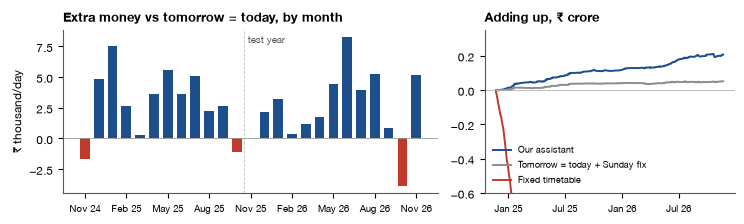

In [4]:
oos = R.copy(); oos["gain"] = oos.blend_2 - oos.today_2
mon = oos.groupby(oos.index.to_period("M")).gain.mean()
M["months_positive"] = int((mon > 0).sum()); M["months_total"] = int(len(mon))
fig, axs = plt.subplots(1, 2, figsize=(7.4, 2.3), gridspec_kw={"width_ratios": [1.5, 1]})
axs[0].bar(range(len(mon)), mon.values / 1000, color=[ACC if v > 0 else RED for v in mon.values], width=0.7)
axs[0].set_xticks(range(0, len(mon), 3)); axs[0].set_xticklabels([str(p.strftime("%b %y")) for p in mon.index[::3]], fontsize=7)
axs[0].axhline(0, color="0.6", lw=0.6); axs[0].axvline(11.5, color="0.75", lw=0.6, ls="--"); axs[0].text(11.8, axs[0].get_ylim()[1] * 0.88, "test year", fontsize=7, color="0.35")
axs[0].set_ylabel("₹ thousand/day"); axs[0].set_title("Extra money vs tomorrow = today, by month")
for col, lbl, c in [("blend_2", "Our assistant", ACC), ("today_sun_2", "Tomorrow = today + Sunday fix", GREY), ("fixed", "Fixed timetable", RED)]:
    axs[1].plot(oos.index, (oos[col] - oos.today_2).cumsum() / 1e7, color=c, lw=1.4, label=lbl)
axs[1].set_ylim(-0.6, 0.35); axs[1].axhline(0, color="0.7", lw=0.6); axs[1].legend(frameon=False, fontsize=6.5, loc="lower left")
axs[1].set_title("Adding up, ₹ crore"); axs[1].xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=[1, 7])); axs[1].xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %y")); axs[1].tick_params(axis="x", labelsize=7)
fig.tight_layout(); fig.savefig(FIG / "m4_monthly.png", dpi=250); plt.show()

## 4. Where does the gain come from?
**What we ask:** which seasons and weekdays gain most, and how often does the assistant use the second round?

In [5]:
t = R[R.split == "test"].copy(); m_ = t.index.month
t["season"] = np.select([m_.isin([3, 4, 5, 6]), m_.isin([7, 8, 9])], ["Mar–Jun", "Jul–Sep"], "Oct–Feb")
t["dow"] = t.index.day_name().str[:3]
seg = pd.concat([t.groupby("season").apply(lambda g: pd.Series({"extra ₹/day": (g.blend_2 - g.today_2).mean(), "share of best": g.blend_2.sum() / g.perfect_2.sum()})),
                 t.groupby("dow").apply(lambda g: pd.Series({"extra ₹/day": (g.blend_2 - g.today_2).mean(), "share of best": g.blend_2.sum() / g.perfect_2.sum()}))])
display(seg.round(3))
M["segments"] = {k: {"gain": round(float(v["extra ₹/day"])), "share": round(float(v["share of best"]), 3)} for k, v in seg.iterrows()}
two = []
for i in np.where(split == "test")[0]:
    c, dd = bt.solve(FB[i], DEG, 2); two.append(dd.sum() / bt.ED > 18.5)
M["share_days_two_rounds"] = round(float(np.mean(two)), 3)
print("days the assistant runs a second round:", f"{M['share_days_two_rounds']:.0%}")

,extra ₹/day,share of best
Jul–Sep,3348.081,0.943
Mar–Jun,3876.673,0.939
Oct–Feb,1104.925,0.965
Fri,1232.735,0.954
Mon,3314.291,0.958
Sat,2628.951,0.964
Sun,7219.193,0.912
Thu,-1894.567,0.938
Tue,3279.567,0.967
Wed,2396.604,0.952


days the assistant runs a second round: 57%


## 5. Does it hold if our assumptions change?
**What we ask:** our wear cost (₹1,000/MWh) is an estimate, exchange fees were left out, and the battery size is assumed.
We re-run the whole test year under other settings.

In [6]:
tst = np.where(split == "test")[0]
def year(F, cyc=2, **kw):
    out = []
    for i in tst:
        c, dd, _ = bt.solve_custom(F[i], cycles=cyc, **kw); out.append(bt.settle_custom(c, dd, ACT[i], kw.get("deg", DEG), kw.get("fee", 0.0)))
    return float(np.mean(out))
sens = []
for lbl, kw in [("Wear ₹0/MWh", {"deg": 0}), ("Wear ₹500/MWh", {"deg": 500}), ("Wear ₹1,000/MWh (base)", {"deg": 1000}), ("Wear ₹1,500/MWh", {"deg": 1500}),
                ("Exchange fee ₹20/MWh each way", {"deg": 1000, "fee": 20}), ("4-hour battery (10 MW / 40 MWh)", {"deg": 1000, "mwh": 40}),
                ("Round-trip efficiency 85%", {"deg": 1000, "rte": 0.85})]:
    a, b, p_ = year(FB, **kw), year(Y1, **kw), year(ACT, **kw)
    sens.append({"setting": lbl, "assistant ₹/day": round(a), "tomorrow = today ₹/day": round(b), "extra ₹/day": round(a - b), "share of best": round(a / p_, 3)})
sens = pd.DataFrame(sens).set_index("setting"); display(sens)
M["sensitivity"] = sens.reset_index().to_dict("records")

,assistant ₹/day,tomorrow = today ₹/day,extra ₹/day,share of best
setting,,,,
Wear ₹0/MWh,150664,147971,2693,0.959
Wear ₹500/MWh,136954,134703,2250,0.955
"Wear ₹1,000/MWh (base)",123997,121401,2597,0.951
"Wear ₹1,500/MWh",111462,108237,3225,0.946
Exchange fee ₹20/MWh each way,122912,120271,2641,0.951
4-hour battery (10 MW / 40 MWh),206471,203254,3217,0.963
Round-trip efficiency 85%,120062,117370,2691,0.950


**What we see:** the assistant stays ahead of *tomorrow = today* under every setting we tried.

## 6. Risk on bad days
**What we ask:** a trader is judged on bad days too. How bad are the worst days and months?

,"worst 5% of days, ₹","worst month avg, ₹/day",losing days
today_2,39371,82854,0
blend_2,39734,84022,0
fixed,12981,27575,2


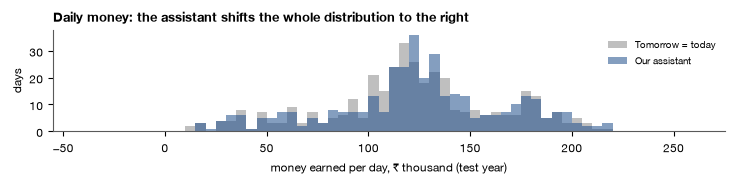

In [7]:
risk = {}
for k in ["today_2", "blend_2", "fixed"]:
    s_ = t[k]; risk[k] = {"worst 5% of days, ₹": round(float(s_.quantile(0.05))), "worst month avg, ₹/day": round(float(s_.groupby(s_.index.to_period("M")).mean().min())),
                          "losing days": int((s_ < 0).sum())}
M["risk"] = risk; display(pd.DataFrame(risk).T)
fig, ax = plt.subplots(figsize=(7.4, 1.9))
bins = np.linspace(-40, 260, 61)
ax.hist(t.today_2 / 1000, bins=bins, color=GREY, alpha=0.55, label="Tomorrow = today"); ax.hist(t.blend_2 / 1000, bins=bins, color=ACC, alpha=0.55, label="Our assistant")
ax.set_xlabel("money earned per day, ₹ thousand (test year)"); ax.set_ylabel("days"); ax.legend(frameon=False, fontsize=7)
ax.set_title("Daily money: the assistant shifts the whole distribution to the right")
fig.tight_layout(); fig.savefig(FIG / "m4_risk.png", dpi=250); plt.show()

## 7. One day up close
**What we ask:** what does the assistant actually do on a day? We show a winter test-year day with a morning and an evening peak.

/var/folders/jl/l9c4dlxs6vlb66jgtdx4gkxc0000gn/T/ipykernel_33924/2132258760.py:1: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  cand = [i for i in tst if days[i].month in (12, 1) and days[i].dayofweek < 5]


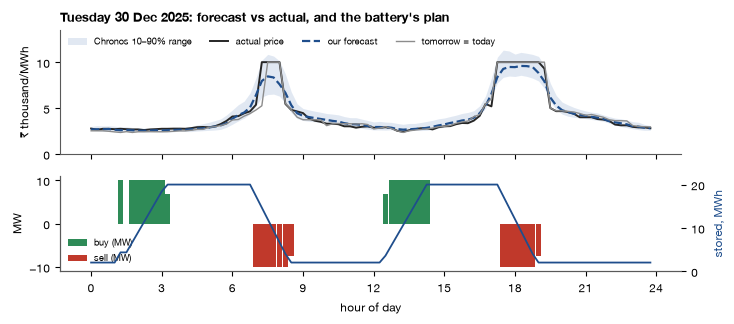

{'date': '2025-12-30', 'assistant': 168023, 'today': 165908, 'perfect': 169002}


In [8]:
cand = [i for i in tst if days[i].month in (12, 1) and days[i].dayofweek < 5]
gains = np.array([R.blend_2.iloc[i] - R.today_2.iloc[i] for i in cand]); pick = cand[int(np.argsort(gains)[len(gains) // 2 + len(gains) // 4])]
DAY = days[pick]; c, dd, soc = bt.solve_custom(FB[pick], cycles=2)
x = np.arange(96) / 4
fig, axs = plt.subplots(2, 1, figsize=(7.4, 3.3), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
axs[0].fill_between(x, CQ[pick, :, 0] / 1000, CQ[pick, :, 8] / 1000, color=MID, alpha=0.2, lw=0, label="Chronos 10–90% range")
axs[0].plot(x, ACT[pick] / 1000, color="0.15", lw=1.4, label="actual price"); axs[0].plot(x, FB[pick] / 1000, color=ACC, lw=1.6, ls="--", label="our forecast")
axs[0].plot(x, Y1[pick] / 1000, color=GREY, lw=1.0, label="tomorrow = today")
axs[0].set_ylabel("₹ thousand/MWh"); axs[0].legend(frameon=False, fontsize=6.6, ncol=4, loc="upper left", bbox_to_anchor=(0, 1.02)); axs[0].set_ylim(0, 13.5)
axs[0].set_title(f"{DAY:%A %d %b %Y}: forecast vs actual, and the battery's plan")
axs[1].bar(x, c * 4, width=0.24, color="#2e8b57", label="buy (MW)"); axs[1].bar(x, -dd * 4, width=0.24, color=RED, label="sell (MW)")
ax2 = axs[1].twinx(); ax2.plot(x, soc, color=ACC, lw=1.3); ax2.set_ylabel("stored, MWh", color=ACC); ax2.set_ylim(0, 22); ax2.spines["top"].set_visible(False)
axs[1].set_ylabel("MW"); axs[1].set_xlabel("hour of day"); axs[1].legend(frameon=False, fontsize=6.6, loc="lower left"); axs[1].set_xticks(range(0, 25, 3))
fig.tight_layout(); fig.savefig(FIG / "m4_day.png", dpi=250); plt.show()
M["example_day"] = {"date": str(DAY.date()), "assistant": round(float(R.blend_2.iloc[pick])), "today": round(float(R.today_2.iloc[pick])), "perfect": round(float(R.perfect_2.iloc[pick]))}
print(M["example_day"])

## 8. Tomorrow's actual bid
**What we ask:** run the full assistant for the first day after our data ends, exactly as a trader would.

In [9]:
import warnings; warnings.filterwarnings("ignore")
import forecast as fc
NEXT = P.index.max() + pd.Timedelta(days=1)
Pext = pd.concat([P, pd.DataFrame(np.nan, index=[NEXT], columns=P.columns)]); cal = fc.calendar(Pext.index)
lear_next = np.mean([fc._fit_predict_window(Pext, cal, NEXT, 1, w)[1][0] for w in fc.WINDOWS], axis=0)
import torch
from chronos import BaseChronosPipeline
pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu", torch_dtype=torch.float32)
q, _ = pipe.predict_quantiles(torch.tensor(P.values.ravel()[-2048:].astype(np.float32))[None], prediction_length=96, quantile_levels=[0.1, 0.5, 0.9])
q = q.numpy()[0]; next_fc = W * lear_next + (1 - W) * q[:, 1]
c, dd, soc = bt.solve_custom(next_fc, cycles=2)
bid = pd.DataFrame({"block": range(1, 97), "time": [f"{h // 4:02d}:{15 * (h % 4):02d}" for h in range(96)],
                    "forecast_rs_mwh": next_fc.round(0), "low_rs_mwh": q[:, 0].round(0), "high_rs_mwh": q[:, 2].round(0),
                    "buy_mw": (c * 4).round(2), "sell_mw": (dd * 4).round(2), "stored_mwh": soc.round(2)})
bid.to_csv(ROOT / f"outputs/bid_{NEXT.date()}.csv", index=False)
M["next_day"] = {"date": str(NEXT.date()), "expected_profit": round(bt.settle_custom(c, dd, next_fc)), "buy_mwh": round(float(c.sum()), 1), "sell_mwh": round(float(dd.sum()), 1)}
print(M["next_day"]); display(bid[(bid.buy_mw > 0) | (bid.sell_mw > 0)].head(12))

W1122 14:10:54.627000 33924 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

{'date': '2026-11-22', 'expected_profit': 126021, 'buy_mwh': 38.4, 'sell_mwh': 33.8}


,block,time,forecast_rs_mwh,low_rs_mwh,high_rs_mwh,buy_mw,sell_mw,stored_mwh
10,11,02:30,2801.0,2576.0,3107.0,10.00,0.00,4.35
11,12,02:45,2817.0,2594.0,3131.0,10.00,0.00,6.69
12,13,03:00,2814.0,2645.0,3206.0,10.00,0.00,9.04
13,14,03:15,2827.0,2655.0,3228.0,6.75,0.00,10.62
14,15,03:30,2814.0,2647.0,3259.0,10.00,0.00,12.96
15,16,03:45,2798.0,2617.0,3282.0,10.00,0.00,15.31
16,17,04:00,2778.0,2503.0,3253.0,10.00,0.00,17.65
17,18,04:15,2731.0,2409.0,3280.0,10.00,0.00,20.00
25,26,06:15,4653.0,3896.0,5866.0,0.00,7.54,17.99
26,27,06:30,5289.0,4275.0,6515.0,0.00,10.00,15.33


In [10]:
json.dump(M, open(ROOT / "outputs/m4_metrics.json", "w"), indent=1, default=float)
R.to_csv(ROOT / "outputs/m4_daily_results.csv")
print("saved outputs/m4_metrics.json and outputs/m4_daily_results.csv")

saved outputs/m4_metrics.json and outputs/m4_daily_results.csv
